In [1]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
#Set time to extract historical data
years = 15
endDate = dt.datetime(2023, 9, 30)   # fixed so results are reproducible and match the other notebooks
startDate = endDate - dt.timedelta(days = 365*years)


In [3]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [4]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate, auto_adjust = False, progress = False)
    adj_close_df[ticker] = data['Adj Close'].squeeze()
print(adj_close_df)

                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2008-10-03   79.637978  43.676712   82.589996   31.118191   39.761795
2008-10-06   75.581741  43.326080   84.279999   29.982853   38.376438
2008-10-07   72.196739  43.452564   87.269997   28.082060   36.033665
2008-10-08   70.377937  42.808781   89.419998   27.858433   35.344631
2008-10-09   65.462799  41.475365   89.900002   27.110153   33.125156
...                ...        ...         ...         ...         ...
2023-09-25  416.843506  62.013939  177.699997  353.581909  206.444519
2023-09-26  410.719482  61.951862  176.279999  348.272400  203.470612
2023-09-27  410.883423  61.730236  174.100006  349.088470  203.682373
2023-09-28  413.265564  61.889812  173.229996  352.008667  205.029739
2023-09-29  412.262573  61.863235  171.449997  352.264374  204.433029

[3773 rows x 5 columns]


In [5]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2008-10-06 -0.052276 -0.008060  0.020256 -0.037167 -0.035463
2008-10-07 -0.045820  0.002915  0.034862 -0.065495 -0.062990
2008-10-08 -0.025515 -0.014927  0.024338 -0.007995 -0.019307
2008-10-09 -0.072398 -0.031644  0.005354 -0.027227 -0.064853
2008-10-10 -0.024555 -0.030963 -0.077210 -0.006365 -0.029329
...              ...       ...       ...       ...       ...
2023-09-25  0.004196 -0.007407 -0.005164  0.004739  0.004017
2023-09-26 -0.014800 -0.001002 -0.008023 -0.015130 -0.014510
2023-09-27  0.000399 -0.003584 -0.012444  0.002340  0.001040
2023-09-28  0.005781  0.002582 -0.005010  0.008330  0.006593
2023-09-29 -0.002430 -0.000430 -0.010329  0.000726 -0.002915

[3772 rows x 5 columns]


In [6]:
#create a function to calculate portfolio expected return
def expected_return(weights, log_returns):
    return np.sum(log_returns.mean()*weights) #Note that expected return are based on historical data. Ideally a market expert comes up with their own expected returns based on current market data


In [7]:
#Define standard deviation
def standard_deviation(weights, cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)

In [8]:
#Create covariance matrix
cov_matrix = log_returns.cov()
print(cov_matrix)

              SPY           BND       GLD           QQQ           VTI
SPY  1.621191e-04  7.477735e-07  0.000010  1.665605e-04  1.630002e-04
BND  7.477735e-07  1.046683e-05  0.000009  4.210509e-07  6.307121e-07
GLD  9.744482e-06  8.564625e-06  0.000111  9.169772e-06  1.047511e-05
QQQ  1.665605e-04  4.210509e-07  0.000009  1.993326e-04  1.686469e-04
VTI  1.630002e-04  6.307121e-07  0.000010  1.686469e-04  1.657456e-04


In [9]:
#Create a equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
portfolio_expected_return = expected_return(weights, log_returns)
portfolio_std_dev = standard_deviation(weights, cov_matrix)

In [10]:
#random Z score generator
def random_z_score():
    return np.random.normal(0,1)

In [11]:
days = 30
def scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days):
    return portfolio_value * portfolio_expected_return * days + portfolio_value * portfolio_std_dev * z_score * np.sqrt(days)

In [12]:
np.random.seed(42)   # reproducible simulations
#run 10000 simulations
simulations = 10000
scenarioReturn = []

for i in range(simulations):
    z_score = random_z_score()
    scenarioReturn.append(scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days))

In [13]:
#specify confidence interval
confidence_interval = 0.99
VaR = -np.percentile(scenarioReturn, 100*(1-confidence_interval))
print(VaR)

94769.22643799752


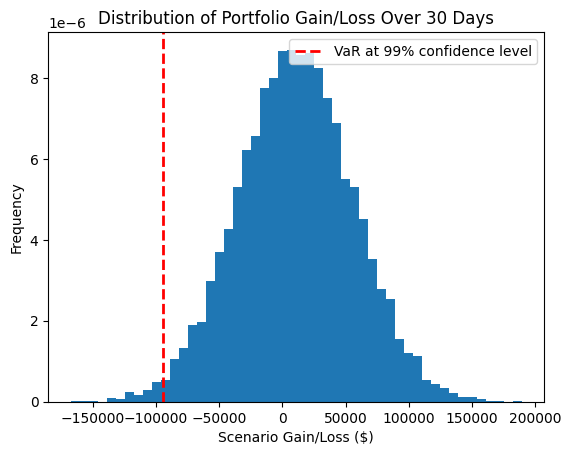

In [14]:
### Plot the results of all 10000 scenarios
plt.hist(scenarioReturn, bins=50, density=True)
plt.xlabel('Scenario Gain/Loss ($)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio Gain/Loss Over {days} Days')
plt.axvline(-VaR, color='r', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()

## Expected Shortfall (Monte Carlo)
ES is the average of the simulated losses beyond VaR.

In [15]:
scenarios = np.array(scenarioReturn)
print(f'{"Confidence":<12}{"30-day VaR":>16}{"30-day ES":>16}')
for cl in [0.95, 0.99]:
    var_cut = np.percentile(scenarios, 100 * (1 - cl))
    print(f'{cl:<12.0%}{-var_cut:>16,.2f}{-scenarios[scenarios <= var_cut].mean():>16,.2f}')

Confidence        30-day VaR       30-day ES
95%                64,486.38       83,616.34
99%                94,769.23      111,887.44
